# T3.2 Leakage: artificial gradient

**Purpose** (Table 4.2, D-5 validation plan): similar to T3.1 Leakage: no gradient, but now a linear slope is introduced in the azimuthal NRCS to confirm
whether artificial gradients, in tandem with the other components (geometric Doppler and beam pattern), will indeed result in leakage, and whether
the leakage correction resolves it.

**Implementation**
1. Estimate SWB geometric Doppler and beam pattern
2. Generate an NRCS field with a linear gradient using an NRCS GMF
3. Estimate leakage
4. Correct the leakage with SCA's own NRCS, as in the uncertainty notebooks

**Requirements**: reference simulation SWB-SCA (California geometry), NRCS GMF (CMOD5.N), EUMETSAT beam pattern

This notebook performs the test and reports the results for interpretation. No tolerances or pass/fail criteria are applied.

The NRCS is $\sigma^0(x, r) = \sigma^0_{CMOD5.N}(r)\,10^{\,g\,x/10}$, i.e. linear in dB along azimuth, with $g$ in dB/km. The leakage is the phase of the geometric
Doppler phasors weighted by the received power, normalised by its sum, so only the relative gradient matters: a slope linear in dB gives every footprint the same weights.

In [1]:
import numpy as np
import xarray as xr
import pandas as pd
from matplotlib import pyplot as plt

from stereoid.oceans.forward_models.cmod5n import cmod5n_forward
from sca_module.readers import create_dataset
from sca_module.dopsca_setup import DopSCAConfig
from sca_module.simulate_L1 import compute_cube_observation_geometry, compute_observations, create_observation_cube, compute_lpf_cube, add_L1_uncertainties, multilook_nrcs_to_grid

plt.rcParams.update({'font.size': 10, 'font.weight' : 'bold'})

## 0 - Parameters

In [2]:
sca = DopSCAConfig()
sca.Lambda = sca.get_wavelength()
# The magic_divider is an unnecessary, but convenient, method to resample the input data to some common sampling.
sca.grid_spacing_target = sca.get_grid_spacing_target(magic_divider=2)

# the NRCS level is irrelevant for leakage (it cancels in the beam weights), only its shape along azimuth matters
wind_direction_wrt_sensor = 45 # [deg], fixed wind direction w.r.t. the look direction for CMOD5.N

gradients = np.array([-0.1, -0.05, -0.01, -0.001, 0, 0.001, 0.01, 0.05, 0.1]) # azimuthal NRCS gradient [dB/km]

## 1 - Load data
Only the geometry (ground range, incidence) of the SWB simulation is used.

In [3]:
files_cali = [
    '/Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/data/SWB_input_California.nc',
    '/Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/data/SWB_output_California.nc'
]

simulation = xr.open_mfdataset(files_cali, compat='no_conflicts', engine='netcdf4').sel(sat = 'S1').compute()
sca.magic_offset = sca.get_magic_offset(incidence_min=simulation.inc.min().data)

# clipping unreasonable incidence angles
simulation = simulation.sel(grg = slice(sca.grg_min - sca.magic_offset, sca.grg_max - sca.magic_offset))
simulation = simulation.assign_coords(grg = simulation.grg + sca.magic_offset)

# Here we interpolate to finer grid spacing,
new_az = np.arange(simulation.az.min(), simulation.az.max(), sca.grid_spacing_target)
new_grg = np.arange(simulation.grg.min(), simulation.grg.max(), sca.grid_spacing_target)
simulation = simulation.interp(az=new_az, grg=new_grg)

# EUMETSAT beam pattern, as in the uncertainty notebooks
beam_SCA = xr.open_dataset('/Users/opodriscoll/Documents/projects/DopSCA MOMS/data/beam_pattern_updated.nc')['beam_sca']

## 2 - NRCS with a gradient linear in dB along azimuth
CMOD5.N for the configured wind speed and a fixed direction at each ground range, times a slope linear in dB along azimuth, centred on the scene.

In [4]:
inc_deg = np.degrees(simulation[sca.var_inc].data)
sigma0_range = cmod5n_forward(
    v=np.full_like(inc_deg, sca.U),
    phi=np.full_like(inc_deg, wind_direction_wrt_sensor),
    theta=inc_deg,
)
az_centred = simulation.az.data - simulation.az.data.mean()

def nrcs_with_gradient(gradient):
    return sigma0_range[None, :] * 10 ** (gradient * az_centred[:, None] / 1e3 / 10)

## 3 - Estimate and correct leakage
No geophysical Doppler is included, so the beam integrated velocity is the leakage only. As in the Monte Carlo notebooks, `add_L1_uncertainties`
adds speckle to the scatterometer NRCS; the leakage is then re-estimated from this speckled NRCS, multi-looked onto the input grid, and subtracted from
the incurred leakage. Both are low-pass filtered to the product resolution, keeping only product cells whose whole footprint is available.
The same noise realisation is used for every gradient.

In [5]:
inc_2d = np.degrees(simulation[sca.var_inc].expand_dims(dim={sca.dim_az: simulation.az.data}))
grg_uniform = np.arange(simulation.grg.min(), simulation.grg.max(), sca.grid_spacing_slant_range_SCA)

def leakage_with_correction(gradient):
    nrcs = nrcs_with_gradient(gradient)
    data = create_dataset(
        nrcs=nrcs,
        dop=np.zeros_like(nrcs),
        inc=inc_2d.data,
        grg=simulation.grg.data,
        az=simulation.az.data,
        grid_spacing=sca.grid_spacing_target,
    )

    data_cube = create_observation_cube(data, sca.az_footprint_cutoff, sca.grid_spacing_target, sca.v_sat_ground, sca.PRF, dropna=False).compute()
    data_cube = compute_cube_observation_geometry(data_cube, sca.dim_az_beam, sca.dim_az_slow_time, sca.dim_range, sca.var_inc, sca.z0, sca.boresight_elevation_angle_scat)

    data_cube = data_cube.transpose(sca.dim_az_slow_time, sca.dim_az_beam, sca.dim_range)
    data_cube['beam']= beam_SCA.interp(az_beam=data_cube.az_beam, grg=data_cube.grg, method='linear')

    data_cube = compute_observations(data_cube, sca.var_nrcs, sca.var_inc, sca.dim_az_beam, sca.v_sat_orbit, sca.Lambda, sca.T_pp, var_azimuth_angle_wrt_boresight = "az_angle_wrt_boresight_ground")
    data_cube = data_cube.transpose(sca.dim_az_slow_time, sca.dim_az_beam, sca.dim_range)

    ds = add_L1_uncertainties(
        ds = data_cube,
        dim_range = sca.dim_range,
        dim_az_beam = sca.dim_az_beam,
        v_sat_orbit = sca.v_sat_orbit,
        U = sca.U,
        sat_height = sca.z0,
        T_pp= sca.T_pp,
        Lambda = sca.Lambda,
        fixed_SCR=None, # < -------- here we let the SCR be calculated from the NRCS data
        grid_spacing_slant_range=sca.grid_spacing_slant_range_SCA,
        random_state=sca.random_state
    )

    # -- Resample to uniform ground-range spacing
    ds = ds[["V_leakage_pulse_rg", "nrcs_scat_speckle"]].interp(grg=grg_uniform, method=sca.interpolator).astype("float32")
    ds = ds.transpose(sca.dim_az_slow_time, sca.dim_range)

    # -- Repeat the leakage estimation, but now using a realization of SCA's estimated NRCS
    data['nrcs_scat_speckle'] = multilook_nrcs_to_grid(ds, data)  # averaged along range over one grid cell, not point-sampled

    data_cube_ = create_observation_cube(data, sca.az_footprint_cutoff, sca.grid_spacing_target, sca.v_sat_ground, sca.PRF, dropna=False).compute()
    data_cube_ = compute_cube_observation_geometry(data_cube_, sca.dim_az_beam, sca.dim_az_slow_time, sca.dim_range, sca.var_inc, sca.z0, sca.boresight_elevation_angle_scat)

    data_cube_ = data_cube_.transpose(sca.dim_az_slow_time, sca.dim_az_beam, sca.dim_range)
    data_cube_['beam']= beam_SCA.interp(az_beam=data_cube_.az_beam, grg=data_cube_.grg, method='linear')

    # here we use 'nrcs_scat_speckle' as the input NRCS, rather than the noise-free version
    data_cube_ = compute_observations(data_cube_, 'nrcs_scat_speckle', sca.var_inc, sca.dim_az_beam, sca.v_sat_orbit, sca.Lambda, sca.T_pp, var_azimuth_angle_wrt_boresight = "az_angle_wrt_boresight_ground")
    data_cube_ = data_cube_[["V_leakage_pulse_rg"]].interp(grg=grg_uniform, method=sca.interpolator).astype("float32")
    data_cube_ = data_cube_.transpose(sca.dim_az_slow_time, sca.dim_range)

    mask_2 = data_cube_["V_leakage_pulse_rg"].notnull()
    ds_filt = data_cube_.where(mask_2, drop=True)

    ds['V_leakage_pulse_rg_net'] = - ds_filt['V_leakage_pulse_rg'] + ds['V_leakage_pulse_rg']

    ds = compute_lpf_cube(
        ds,
        resolution_product= sca.resolution_product,
        fs_x=1 / data_cube.attrs["stride"],
        fs_y=1 / sca.grid_spacing_slant_range_SCA,
        data_2_lpf=["V_leakage_pulse_rg", "V_leakage_pulse_rg_net"],
        window=sca.product_averaging_window,
        crop_edges = True,
        min_footprint_coverage = 1, # only product cells whose whole footprint is available
    )

    # incurred and residual leakage over the same product cells
    evaluate = ds["V_leakage_pulse_rg_lpf"].notnull() & ds["V_leakage_pulse_rg_net_lpf"].notnull()
    return ds["V_leakage_pulse_rg_lpf"].where(evaluate), ds["V_leakage_pulse_rg_net_lpf"].where(evaluate)

corrected = {gradient: leakage_with_correction(gradient) for gradient in gradients}

# Results
## Spatial illustration
For one gradient: the simulated NRCS, the incurred leakage and the leakage after correction, both at 50 km on the same colour scale.

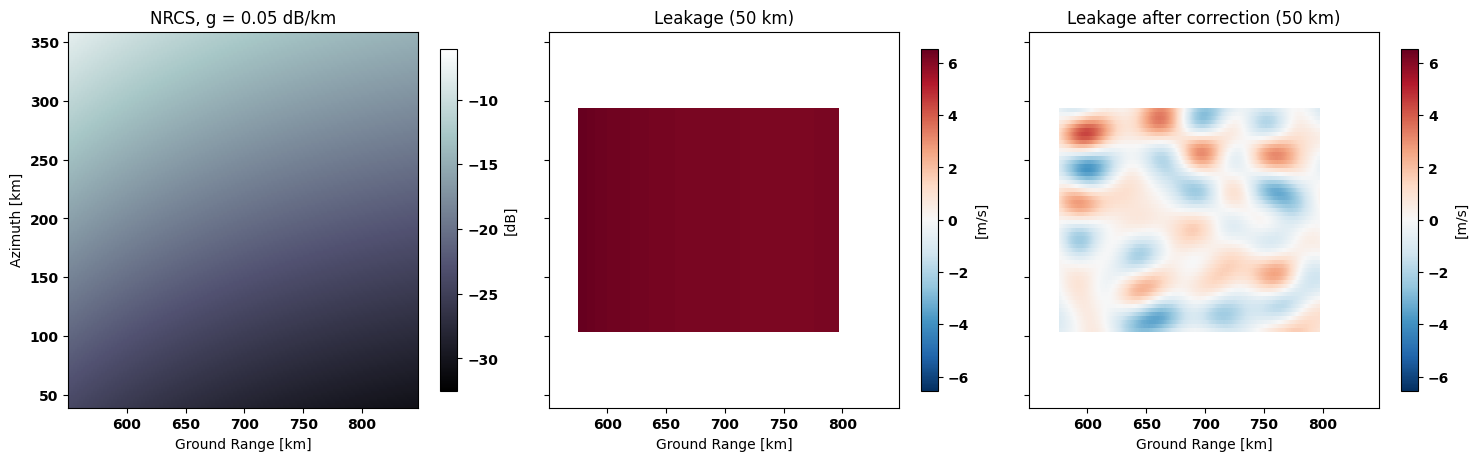

In [6]:
gradient_map = 0.05 # [dB/km]
incurred, residual = corrected[gradient_map]
to_km = lambda da: da.assign_coords({name: da[name] / 1e3 for name in da.dims})
nrcs_map = xr.DataArray(nrcs_with_gradient(gradient_map), dims=(sca.dim_az, sca.dim_range), coords={sca.dim_az: simulation.az.data, sca.dim_range: simulation.grg.data})
lim = float(np.abs(incurred).max())

fig, axes = plt.subplots(ncols=3, nrows=1, sharex=True, sharey=True, figsize = (15, 6))
(10 * np.log10(to_km(nrcs_map))).plot(ax = axes[0], x = sca.dim_range, cmap = 'bone', cbar_kwargs={"label": "[dB]", "shrink" : 0.6})
to_km(incurred).plot(ax = axes[1], x = sca.dim_range, cmap = 'RdBu_r', vmin = -lim, vmax = lim, cbar_kwargs={"label": "[m/s]", "shrink" : 0.6})
to_km(residual).plot(ax = axes[2], x = sca.dim_range, cmap = 'RdBu_r', vmin = -lim, vmax = lim, cbar_kwargs={"label": "[m/s]", "shrink" : 0.6})
_ = axes[0].set_title(f"NRCS, g = {gradient_map} dB/km")
_ = axes[1].set_title("Leakage (50 km)")
_ = axes[2].set_title("Leakage after correction (50 km)")
for ax in axes:
    ax.set_aspect('equal')
    ax.set_xlabel("Ground Range [km]")
    ax.set_ylabel("")
_ = axes[0].set_ylabel("Azimuth [km]")
plt.tight_layout()

## Leakage correction
Incurred and residual leakage at 50 km over all evaluated product cells, in m/s. The residual after correction comes from the speckle of the NRCS used to
re-estimate the leakage: the correction sees the gradient through a speckled NRCS. Its mean shows whether the gradient is resolved, its RMS the
speckle-induced error.

In [7]:
correction = pd.DataFrame(
    {
        "incurred, mean": [float(incurred.mean()) for incurred, _ in corrected.values()],
        "residual, mean": [float(residual.mean()) for _, residual in corrected.values()],
        "residual, RMS": [float(np.sqrt((residual**2).mean())) for _, residual in corrected.values()],
    },
    index=pd.Index(gradients, name="g [dB/km]"),
)
correction

,"incurred, mean","residual, mean","residual, RMS"
g [dB/km],,,
-0.100,-13.542264,-0.012791,1.280193
-0.050,-6.950998,-0.010867,1.281232
-0.010,-1.671918,-0.008843,1.281235
-0.001,-0.483891,-0.008278,1.281163
0.000,-0.351888,-0.008216,1.281150
0.001,-0.219886,-0.008152,1.281138
0.010,0.968106,-0.007544,1.281041
0.050,6.246321,-0.004428,1.280251
0.100,12.834889,0.000036,1.278036


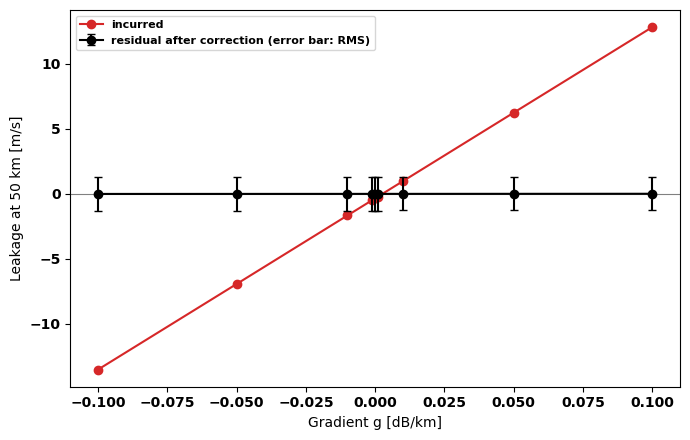

In [8]:
fig, ax = plt.subplots(figsize = (7, 4.5))
ax.plot(gradients, correction["incurred, mean"], marker = 'o', color = 'C3', label = "incurred")
ax.errorbar(gradients, correction["residual, mean"], yerr = correction["residual, RMS"], marker = 'o', color = 'k', capsize = 3, label = "residual after correction (error bar: RMS)")
ax.axhline(0, color = 'grey', lw = 0.8)
ax.set_xlabel("Gradient g [dB/km]")
ax.set_ylabel("Leakage at 50 km [m/s]")
ax.legend(fontsize = 8)
plt.tight_layout()